# Sistemas de recomendación de películas: SVD, modelo híbrido y agente LLM (MovieLens 1M)

Recomendador de películas construido sobre las calificaciones de MovieLens 1M (1,000,209 calificaciones de 6,040 usuarios). Compara factorización matricial (SVD truncado y ALS), un modelo híbrido con contenido y un agente LLM que redacta las justificaciones. Todo se evalúa sobre datos apartados y contra baselines exigentes.

**Resultados principales**

- **Predicción de calificaciones.** ALS sobre un baseline de sesgos logra un RMSE de 0.868 en test, frente a 0.910 del baseline de sesgo usuario + película (-4.6 %). El SVD centrado solo por usuario (0.968) quedó 6.4 % peor que ese baseline. Elegir k por varianza explicada (k = 559) habría empeorado el RMSE 5.4 % respecto a k = 20.
- **Ranking top-10.** La popularidad es un baseline difícil: NDCG@10 de 0.178 contra 0.142 del SVD con similitud coseno (la diferencia es estadísticamente clara). Pero el SVD acierta casi con la misma frecuencia (tasa de aciertos 0.61 en ambos) y recomienda 19 veces más del catálogo (cobertura de 31 % contra 1.7 %).
- **Contenido y atributos demográficos.** Añadir género y década no mejoró al SVD solo. Añadir sexo y edad empeoró el ranking (NDCG en validación de 0.055 a 0.039).
- **Perfil de cinco favoritas.** Promediar la similitud con las favoritas dejó sin representar, en promedio, 1.8 de 5; recuperar por favorita las cubre todas, a costa de 16-18 % de NDCG.
- **Agente LLM.** Redacta las justificaciones, pero solo elige entre las candidatas que recibe; sus datos se verifican con código.

**Stack:** Python, NumPy, pandas, SciPy, scikit-learn, matplotlib, Gemini API.

## 1. Datos

[MovieLens 1M](https://grouplens.org/datasets/movielens/1m/) (GroupLens): 1,000,209 calificaciones de 1 a 5 hechas por 6,040 usuarios sobre 3,706 películas. El catálogo tiene 3,883 películas, pero 177 nunca fueron calificadas. Cada usuario calificó al menos 20. Hay género de las películas y sexo, edad y ocupación de los usuarios.

In [1]:
# Librerías
import os, re, time, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix, diags
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics.pairwise import cosine_similarity
from IPython.display import Markdown, display

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
SEED = 42

In [2]:
# MovieLens 1M (GroupLens). Si la carpeta ml-1m no existe, se descarga.
DATA_DIR = 'ml-1m'
URL = 'https://files.grouplens.org/datasets/movielens/ml-1m.zip'
if not os.path.exists(os.path.join(DATA_DIR, 'ratings.dat')):
    urllib.request.urlretrieve(URL, 'ml-1m.zip')
    with zipfile.ZipFile('ml-1m.zip') as z:
        z.extractall('.')

user_df = pd.read_csv(f'{DATA_DIR}/users.dat', header=None, sep='::', engine='python',
                      names=['user_id', 'gender', 'age', 'occupation', 'zip'])
rating_df = pd.read_csv(f'{DATA_DIR}/ratings.dat', header=None, sep='::', engine='python',
                        names=['user_id', 'movie_id', 'rating', 'timestamp'])
movie_df = pd.read_csv(f'{DATA_DIR}/movies.dat', header=None, sep='::', engine='python', encoding='latin-1',
                       names=['movie_id', 'title', 'genres'])

print('Usuarios:', len(user_df), '| Calificaciones:', len(rating_df), '| Películas en el catálogo:', len(movie_df))
print('Escala:', np.sort(rating_df.rating.unique()))
print(rating_df.rating.value_counts().sort_index().to_string())

Usuarios: 6040 | Calificaciones: 1000209 | Películas en el catálogo: 3883
Escala: [1 2 3 4 5]
rating
1     56174
2    107557
3    261197
4    348971
5    226310


## 2. Matriz de utilidad

Se trabaja con arreglos de índices y una matriz **dispersa** (CSR): una matriz densa de usuarios por películas guardaría millones de ceros que son datos faltantes ("no vista"), no calificaciones de 0.

In [3]:
users  = rating_df['user_id'].astype('category')
movies = rating_df['movie_id'].astype('category')
ui, mi = users.cat.codes.values.astype(int), movies.cat.codes.values.astype(int)
r = rating_df['rating'].values.astype(float)
n_u, n_m = len(users.cat.categories), len(movies.cat.categories)

names = movie_df.set_index('movie_id')['title'].reindex(movies.cat.categories).tolist()   # título de cada columna
assert len(set(names)) == n_m, 'hay títulos repetidos'
generos = movie_df.set_index('movie_id')['genres'].reindex(movies.cat.categories)
generos.index = names

R_all = csr_matrix((r, (ui, mi)), shape=(n_u, n_m))
dens = len(r) / (n_u * n_m)
print(f'Dimensión: {n_u} usuarios x {n_m} películas con al menos una calificación')
print(f'Elementos: {n_u * n_m:,} | Calificaciones: {len(r):,}')
print(f'Densidad: {dens:.2%} | Dispersión: {1 - dens:.2%}')
print(f'Calificaciones por usuario (media / mín / máx): {len(r) / n_u:.1f} / {np.bincount(ui).min()} / {np.bincount(ui).max()}')
print(f'Calificaciones por película (mediana / máx): {np.median(np.bincount(mi)):.0f} / {np.bincount(mi).max()}')

Dimensión: 6040 usuarios x 3706 películas con al menos una calificación
Elementos: 22,384,240 | Calificaciones: 1,000,209
Densidad: 4.47% | Dispersión: 95.53%
Calificaciones por usuario (media / mín / máx): 165.6 / 20 / 2314
Calificaciones por película (mediana / máx): 124 / 3428


Solo 4.47 % de los 22.4 millones de celdas tiene una calificación (dispersión de 95.53 %). Cada usuario calificó en promedio 165.6 películas, y la mediana de calificaciones por película es 124 pero el máximo es 3,428: pocas películas concentran gran parte de las calificaciones, algo que más adelante importa para el sesgo de popularidad.

## 3. Varianza explicada vs. número de componentes

Primer criterio, el ingenuo: cuántos componentes retener para explicar 80, 90 y 95 % de la varianza de la matriz con ceros imputados.

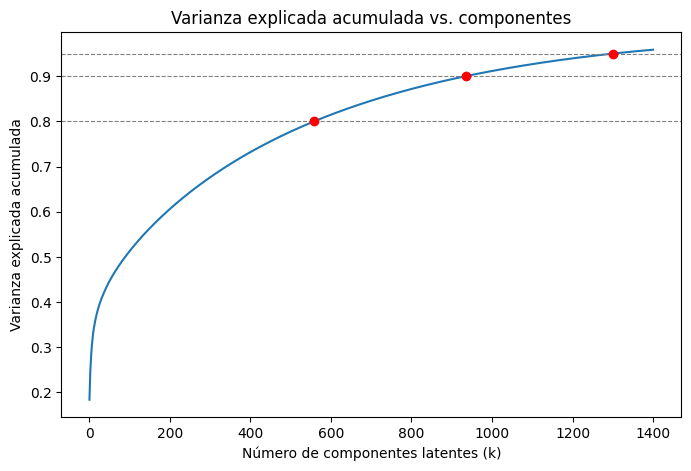

,Tramo,k inicial,k final,Componentes adicionales,Puntos de varianza,Componentes por punto
0,0% -> 80%,0,559,559,80,7.0
1,80% -> 90%,559,935,376,10,37.6
2,90% -> 95%,935,1300,365,5,73.0


80% de la varianza: k = 559 (15.1% de las 3706 películas)
90% de la varianza: k = 935 (25.2% de las 3706 películas)
95% de la varianza: k = 1300 (35.1% de las 3706 películas)


In [4]:
Xt = R_all.T.tocsr()                                   # películas x usuarios (ceros = faltantes)
N_COMP = min(1400, min(Xt.shape) - 1)
svd_t = TruncatedSVD(n_components=N_COMP, random_state=SEED).fit(Xt)
var_acum = np.cumsum(svd_t.explained_variance_ratio_)

ks_var = {}
for u in (0.80, 0.90, 0.95):
    if var_acum[-1] >= u:
        ks_var[u] = int(np.searchsorted(var_acum, u)) + 1
    else:
        print(f'{u:.0%}: no se alcanza con {N_COMP} componentes.')

plt.figure(figsize=(8, 5))
plt.plot(np.arange(1, len(var_acum) + 1), var_acum)
for u, k_u in ks_var.items():
    plt.axhline(u, ls='--', lw=0.8, color='gray')
    plt.scatter(k_u, var_acum[k_u - 1], color='red', zorder=3)
plt.xlabel('Número de componentes latentes (k)'); plt.ylabel('Varianza explicada acumulada')
plt.title('Varianza explicada acumulada vs. componentes'); plt.show()

filas, k_prev, u_prev = [], 0, 0.0
for u, k_u in ks_var.items():
    filas.append({'Tramo': f'{u_prev:.0%} -> {u:.0%}', 'k inicial': k_prev, 'k final': k_u,
                  'Componentes adicionales': k_u - k_prev, 'Puntos de varianza': round((u - u_prev) * 100),
                  'Componentes por punto': round((k_u - k_prev) / ((u - u_prev) * 100), 1)})
    k_prev, u_prev = k_u, u
display(pd.DataFrame(filas))
for u, k_u in ks_var.items():
    print(f'{u:.0%} de la varianza: k = {k_u} ({k_u / Xt.shape[0]:.1%} de las {Xt.shape[0]} películas)')

Se necesitan 559, 935 y 1,300 componentes para explicar 80, 90 y 95 % de la varianza. Pero esa varianza mide qué tan bien se reconstruye una matriz llena de ceros que no son datos; no dice qué tan bien se predicen calificaciones nuevas. La sección 5 lo contrasta con el error sobre datos apartados.

## 4. Protocolo de evaluación

Las calificaciones se dividen al azar en **train (70 %)**, **validación (10 %)** y **test (20 %)**. Todo lo que se ajusta (medias, sesgos, SVD, ALS, similitudes) usa solo train. La validación sirve para elegir k, hiperparámetros y pesos; test se usa una vez por bloque, al final.

In [5]:
rng = np.random.default_rng(SEED)
perm = rng.permutation(len(r))
n_te, n_va = int(0.20 * len(r)), int(0.10 * len(r))
te = np.sort(perm[:n_te]); va = np.sort(perm[n_te:n_te + n_va]); tr = np.sort(perm[n_te + n_va:])
print(f'train {len(tr):,} | validación {len(va):,} | test {len(te):,}')

n_tr_u = np.bincount(ui[tr], minlength=n_u)
print('Usuarios sin calificaciones en train:', int((n_tr_u == 0).sum()),
      '| películas sin calificaciones en train:', int((np.bincount(mi[tr], minlength=n_m) == 0).sum()))

train 700,148 | validación 100,020 | test 200,041
Usuarios sin calificaciones en train: 0 | películas sin calificaciones en train: 45


Todos los usuarios tienen calificaciones en train; 45 películas no, y para ellas los modelos de factores no tienen información.

## 5. Predicción de calificaciones (RMSE)

Se comparan, de menos a más sofisticado:

* **Baselines**: media global, media por usuario, media por película y **sesgo usuario + película** (con regularización). Si un modelo de factores no supera al último, no está aportando.
* **SVD truncado** sobre tres versiones de la matriz de train: con ceros, centrada por usuario y centrada por sesgos. En las dos últimas, un faltante equivale a "la calificación esperada", no a 0.
* **ALS** sobre el residuo de los sesgos: una factorización que optimiza **solo sobre las calificaciones observadas**, con regularización.

In [6]:
def rmse(pred, idx):
    return float(np.sqrt(np.mean((np.clip(pred, 1, 5) - r[idx]) ** 2)))


def ajustar_sesgos(idx, lam_i=10.0, lam_u=15.0, n_iter=5):
    """mu + b_u + b_i con regularización (Koren): los sesgos de usuarios/películas con pocos datos se encogen a 0."""
    mu = r[idx].mean()
    bu, bi = np.zeros(n_u), np.zeros(n_m)
    for _ in range(n_iter):
        bi = np.bincount(mi[idx], weights=r[idx] - mu - bu[ui[idx]], minlength=n_m) / (lam_i + np.bincount(mi[idx], minlength=n_m))
        bu = np.bincount(ui[idx], weights=r[idx] - mu - bi[mi[idx]], minlength=n_u) / (lam_u + np.bincount(ui[idx], minlength=n_u))
    return mu, bu, bi


def medias_por(eje, idx, mu):
    cod = ui if eje == 'u' else mi
    n_e = n_u if eje == 'u' else n_m
    s, c = np.bincount(cod[idx], weights=r[idx], minlength=n_e), np.bincount(cod[idx], minlength=n_e)
    return np.where(c > 0, s / np.maximum(c, 1), mu)


mu, bu, bi = ajustar_sesgos(tr)
umean, imean = medias_por('u', tr, mu), medias_por('i', tr, mu)

def pred_base(nombre, idx):
    if nombre == 'global':   return np.full(len(idx), mu)
    if nombre == 'usuario':  return umean[ui[idx]]
    if nombre == 'pelicula': return imean[mi[idx]]
    if nombre == 'sesgos':   return mu + bu[ui[idx]] + bi[mi[idx]]

tabla_base = pd.DataFrame({
    'Modelo': ['Media global', 'Media por usuario', 'Media por película', 'Sesgo usuario + película'],
    'RMSE val': [rmse(pred_base(n, va), va) for n in ('global', 'usuario', 'pelicula', 'sesgos')],
})
display(tabla_base.round(4))

,Modelo,RMSE val
0,Media global,1.1160
1,Media por usuario,1.0349
2,Media por película,0.9789
3,Sesgo usuario + película,0.9092


En validación, la media por película (0.979) ya mejora a la media por usuario (1.035), y sumar los sesgos de usuario y de película baja el error a 0.909. Ese es el modelo que hay que superar.

SVD con ceros: listo
SVD centrado (usuario): listo
SVD centrado (sesgos): listo


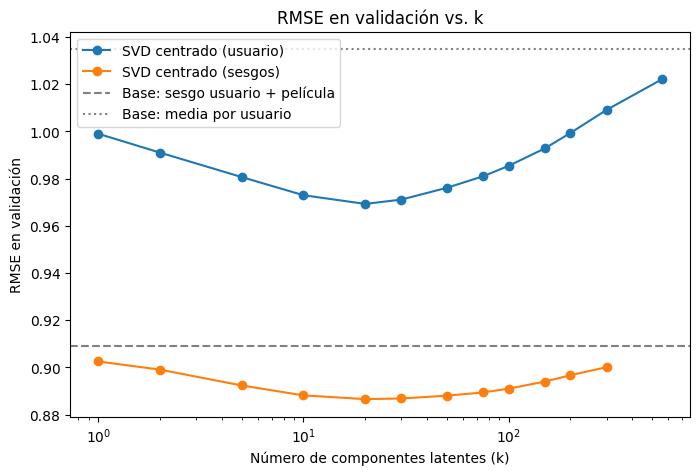

,k en validación,RMSE val
SVD con ceros,20.0,2.5173
SVD centrado (usuario),20.0,0.9693
SVD centrado (sesgos),20.0,0.8866


Con k = 559 (criterio de 80 % de varianza) el RMSE de validación es 1.0221 frente a 0.9693 con k = 20.


In [7]:
def rmse_vs_k(X, base_fn, idx_eval, ks, chunk=20_000):
    """SVD truncado de X (usuarios x películas, solo train). Predicción = base + reconstrucción con k componentes.
    Un solo ajuste con k máximo; la reconstrucción con k menores sale de sumas acumuladas."""
    svd = TruncatedSVD(n_components=max(ks), random_state=SEED).fit(X)
    Vt = svd.components_
    Z = X @ Vt.T                                                   # = U·Σ
    u_e, m_e, y, base = ui[idx_eval], mi[idx_eval], r[idx_eval], base_fn(idx_eval)
    sse = np.zeros(len(ks))
    for s in range(0, len(idx_eval), chunk):
        sl = slice(s, s + chunk)
        cum = np.cumsum(Z[u_e[sl]] * Vt[:, m_e[sl]].T, axis=1)
        for q, k in enumerate(ks):
            sse[q] += ((np.clip(base[sl] + cum[:, k - 1], 1, 5) - y[sl]) ** 2).sum()
    return np.sqrt(sse / len(idx_eval))


def matriz_train(valores):
    return csr_matrix((valores, (ui[tr], mi[tr])), shape=(n_u, n_m))

versiones = {
    'SVD con ceros':          (matriz_train(r[tr]),                                  lambda idx: np.zeros(len(idx))),
    'SVD centrado (usuario)': (matriz_train(r[tr] - umean[ui[tr]]),                  lambda idx: pred_base('usuario', idx)),
    'SVD centrado (sesgos)':  (matriz_train(r[tr] - mu - bu[ui[tr]] - bi[mi[tr]]),   lambda idx: pred_base('sesgos', idx)),
}
k_tope = min(n_u, n_m) - 1
ks_corto = [k for k in (1, 2, 5, 10, 20, 30, 50, 75, 100, 150, 200, 300) if k < k_tope]
ks_largo = ks_corto + ([ks_var[0.80]] if 0.80 in ks_var and ks_var[0.80] < k_tope else [])   # incluye el k "por varianza"

curvas = {}
for nombre, (X, base_fn) in versiones.items():
    ks_m = ks_largo if nombre == 'SVD centrado (usuario)' else ks_corto
    curvas[nombre] = (ks_m, rmse_vs_k(X, base_fn, va, ks_m))
    print(f'{nombre}: listo')

plt.figure(figsize=(8, 5))
for nombre, (ks_m, e) in curvas.items():
    if nombre != 'SVD con ceros':
        plt.plot(ks_m, e, marker='o', label=nombre)
plt.axhline(rmse(pred_base('sesgos', va), va), ls='--', color='gray', label='Base: sesgo usuario + película')
plt.axhline(rmse(pred_base('usuario', va), va), ls=':', color='gray', label='Base: media por usuario')
plt.xscale('log'); plt.xlabel('Número de componentes latentes (k)'); plt.ylabel('RMSE en validación')
plt.title('RMSE en validación vs. k'); plt.legend(); plt.show()

k_mejor = {n: ks_m[int(np.argmin(e))] for n, (ks_m, e) in curvas.items()}
display(pd.DataFrame({n: {'k en validación': k_mejor[n], 'RMSE val': round(float(e.min()), 4)} for n, (ks_m, e) in curvas.items()}).T)
if 0.80 in ks_var:
    ks_m, e = curvas['SVD centrado (usuario)']
    if ks_var[0.80] in ks_m:
        print(f'Con k = {ks_var[0.80]} (criterio de 80 % de varianza) el RMSE de validación es {e[ks_m.index(ks_var[0.80])]:.4f} '
              f'frente a {e.min():.4f} con k = {k_mejor["SVD centrado (usuario)"]}.')

Las tres versiones del SVD logran su menor error en validación con k = 20, no con los 559 componentes del criterio de varianza: para la versión centrada por usuario el RMSE sería 1.022 en lugar de 0.969 (5.4 % peor), probablemente porque los componentes extra ajustan ruido. Con ceros imputados el error es 2.52, porque el modelo lee los faltantes como una calificación de 0.

In [8]:
# ALS sobre el residuo de los sesgos, optimizando solo sobre calificaciones observadas.
def als(idx, k, lam, n_iter=10, seed=SEED):
    res = r[idx] - mu - bu[ui[idx]] - bi[mi[idx]]
    rg = np.random.default_rng(seed)
    P = np.zeros((n_u, k)); Q = 0.1 * rg.standard_normal((n_m, k))
    Rui = csr_matrix((res, (ui[idx], mi[idx])), shape=(n_u, n_m)); Riu = Rui.T.tocsr()
    I = np.eye(k)

    def paso(M, F, fijo):
        for j in range(M.shape[0]):
            a, b = M.indptr[j], M.indptr[j + 1]
            if a == b:
                continue
            Y = fijo[M.indices[a:b]]
            F[j] = np.linalg.solve(Y.T @ Y + lam * (b - a) * I, Y.T @ M.data[a:b])    # regularización ponderada por n° de calificaciones

    for _ in range(n_iter):
        paso(Rui, P, Q); paso(Riu, Q, P)
    return P, Q


def rmse_als(P, Q, idx):
    return rmse(pred_base('sesgos', idx) + np.einsum('ij,ij->i', P[ui[idx]], Q[mi[idx]]), idx)


t0 = time.time()
filas, modelos_als = [], {}
for k_, lam_ in [(20, 0.05), (20, 0.1), (20, 0.2)]:
    P_, Q_ = als(tr, k_, lam_); modelos_als[(k_, lam_)] = (P_, Q_)
    filas.append({'k': k_, 'lambda': lam_, 'RMSE val': rmse_als(P_, Q_, va)})
lam_best = min(filas, key=lambda f: f['RMSE val'])['lambda']
for k_ in (10, 50):
    P_, Q_ = als(tr, k_, lam_best); modelos_als[(k_, lam_best)] = (P_, Q_)
    filas.append({'k': k_, 'lambda': lam_best, 'RMSE val': rmse_als(P_, Q_, va)})
tabla_als = pd.DataFrame(filas).sort_values('RMSE val')
display(tabla_als.round(4))
k_als, lam_als = int(tabla_als.iloc[0]['k']), float(tabla_als.iloc[0]['lambda'])
P_als, Q_als = modelos_als[(k_als, lam_als)]
print(f'ALS elegido en validación: k = {k_als}, lambda = {lam_als} ({time.time() - t0:.0f} s)')

,k,lambda,RMSE val
4,50,0.10,0.8674
1,20,0.10,0.8690
3,10,0.10,0.8709
0,20,0.05,0.8786
2,20,0.20,0.9026


ALS elegido en validación: k = 50, lambda = 0.1 (53 s)


In [9]:
# Resultado final en TEST (una sola vez, con lo elegido en validación). Los modelos se ajustaron solo con train.
res_test = {
    'Media global':              rmse(pred_base('global', te), te),
    'Media por usuario':         rmse(pred_base('usuario', te), te),
    'Media por película':        rmse(pred_base('pelicula', te), te),
    'Sesgo usuario + película':  rmse(pred_base('sesgos', te), te),
}
for nombre, (X, base_fn) in versiones.items():
    k_ = k_mejor[nombre]
    res_test[f'{nombre} (k={k_})'] = float(rmse_vs_k(X, base_fn, te, [k_])[0])
res_test[f'ALS sobre sesgos (k={k_als})'] = rmse_als(P_als, Q_als, te)

tabla_rmse = pd.DataFrame({'RMSE test': res_test})
ref = res_test['Sesgo usuario + película']
tabla_rmse['vs. sesgo usuario + película'] = (tabla_rmse['RMSE test'] / ref - 1).map('{:+.1%}'.format)
display(tabla_rmse.round(4))

,RMSE test,vs. sesgo usuario + película
Media global,1.1157,+22.6%
Media por usuario,1.0346,+13.7%
Media por película,0.9804,+7.8%
Sesgo usuario + película,0.9099,+0.0%
SVD con ceros (k=20),2.5184,+176.8%
SVD centrado (usuario) (k=20),0.9682,+6.4%
SVD centrado (sesgos) (k=20),0.8873,-2.5%
ALS sobre sesgos (k=50),0.8681,-4.6%


**Resultado en test.** El baseline de sesgos (0.910) es la referencia. El SVD centrado solo por usuario (0.968) queda **6.4 % peor**: restar la media del usuario no basta, falta el efecto de la película. Centrar por sesgos baja el error a 0.887 (-2.5 %), y ALS, que ignora los faltantes en vez de rellenarlos, llega a 0.868 (-4.6 %). La mejora sobre el baseline es modesta: gran parte de la señal ya estaba en los sesgos.

## 6. Similitud entre películas y modelo híbrido

**Recomendador colaborativo**: factores latentes de cada película (SVD de la matriz centrada por usuario, transpuesta) y similitud coseno entre películas.

**Recomendador híbrido**: se concatenan bloques normalizados (factores SVD, género multi-hot, década y, opcionalmente, un perfil de audiencia por película) con pesos; el coseno resultante es un promedio ponderado de la similitud de cada bloque.

El perfil de **audiencia** (proporción de mujeres y de menores de 25 años entre quienes calificaron cada película) usa sexo y edad de las personas. Se evalúa si aporta algo; si no mejora el ranking, no hay razón para usar atributos sensibles.

In [10]:
# ---- contenido de las películas (no depende de las calificaciones)
año = pd.Series(names).str.extract(r'\((\d{4})\)\s*$')[0].astype(float)
assert año.notna().all()
decada = ((año // 10) * 10).astype(int).values
D = pd.get_dummies(decada).astype(float).values                                   # década (categórica)
G = generos.reindex(names).fillna('').str.get_dummies(sep='|').values.astype(float)   # género (multi-hot)
GENEROS = list(generos.reindex(names).fillna('').str.get_dummies(sep='|').columns)
print('Décadas:', D.shape[1], '| Géneros:', G.shape[1])

perfil_u = user_df.set_index('user_id').reindex(users.cat.categories)
es_mujer_u = (perfil_u['gender'].values == 'F')
es_joven_u = (perfil_u['age'].values <= 18)                                      # códigos 1 y 18: menores de 25


def unit(M):
    return M / np.maximum(np.linalg.norm(M, axis=1, keepdims=True), 1e-12)


def audiencia(idx, m=20):
    """Proporción de mujeres / jóvenes entre quienes calificaron cada película, suavizada hacia el promedio global."""
    n = np.bincount(mi[idx], minlength=n_m)
    out = []
    for flag in (es_mujer_u, es_joven_u):
        f = flag[ui[idx]].astype(float)
        out.append((np.bincount(mi[idx], weights=f, minlength=n_m) + m * f.mean()) / (n + m))
    return np.column_stack(out)


def factores_svd(idx, k, seed=1):
    """Factores latentes de las películas: SVD de (películas x usuarios) centrada por usuario, solo con las calificaciones idx."""
    s, c = np.bincount(ui[idx], weights=r[idx], minlength=n_u), np.bincount(ui[idx], minlength=n_u)
    um = np.where(c > 0, s / np.maximum(c, 1), r[idx].mean())
    X = csr_matrix((r[idx] - um[ui[idx]], (mi[idx], ui[idx])), shape=(n_m, n_u))
    return TruncatedSVD(n_components=k, random_state=seed).fit_transform(X)


def sim_hibrida(F, pesos, AUD=None):
    bloques = {'svd': F, 'genero': G, 'decada': D}
    if AUD is not None:
        bloques['audiencia'] = AUD
    H = np.hstack([np.sqrt(w) * unit(bloques[b]) for b, w in pesos.items() if w > 0])
    return cosine_similarity(H).astype(np.float32)

Décadas: 10 | Géneros: 18


## 7. Evaluación de ranking

Para cada usuario de evaluación se toman como **semillas** las películas que le gustaron en train (calificación >= 4), se puntúan todas las que no ha visto y se toma el top-10. Una recomendación es **acierto** si el usuario la calificó con >= 4 en el conjunto apartado (validación o test). Las películas no calificadas se tratan como no relevantes, así que las métricas absolutas son bajas; lo informativo es la comparación entre modelos.

Métricas: precision@10, recall@10, NDCG@10, tasa de aciertos (al menos uno), **cobertura** (fracción del catálogo que llega a recomendarse) y número medio de calificaciones de lo recomendado (sesgo de popularidad). Se incluyen los baselines **popularidad** y **aleatorio**. Se evalúa con 1,500 usuarios elegidos al azar de los 5,699 elegibles (al menos 5 películas gustadas en train y una en validación y en test).

In [11]:
def csr_bin(idx, solo_gustadas=False):
    sel = idx[r[idx] >= 4] if solo_gustadas else idx
    return csr_matrix((np.ones(len(sel), dtype=np.float32), (ui[sel], mi[sel])), shape=(n_u, n_m))

B_tr, B_tr_like = csr_bin(tr), csr_bin(tr, True)
B_va, B_va_like = csr_bin(va), csr_bin(va, True)
B_te_like = csr_bin(te, True)
pop_tr = np.asarray(B_tr.sum(0)).ravel()                      # n° de calificaciones por película en train

cuenta = lambda B: np.asarray(B.sum(1)).ravel()
elegibles = np.where((cuenta(B_tr_like) >= 5) & (cuenta(B_va_like) >= 1) & (cuenta(B_te_like) >= 1))[0]
N_EVAL_USERS = 1500
usuarios_eval = np.random.default_rng(SEED).choice(elegibles, size=min(N_EVAL_USERS, len(elegibles)), replace=False)
print(f'Usuarios elegibles: {len(elegibles)} | usuarios de evaluación: {len(usuarios_eval)}')

K = 10
def metricas_topk(scores, users, split):
    vistas = B_tr[users].toarray() > 0
    if split == 'test':
        vistas |= B_va[users].toarray() > 0                    # lo calificado en validación ya es conocido
    sc = np.where(vistas, -np.inf, scores)
    top = np.argpartition(-sc, K, axis=1)[:, :K]
    top = np.take_along_axis(top, np.argsort(-np.take_along_axis(sc, top, 1), axis=1), 1)
    rel = (B_va_like if split == 'val' else B_te_like)[users].toarray() > 0
    aciertos = np.take_along_axis(rel, top, 1)
    n_rel = rel.sum(1)
    desc = 1 / np.log2(np.arange(2, K + 2))
    ndcg = (aciertos * desc).sum(1) / np.array([desc[:min(K, n)].sum() for n in n_rel])
    return {'Precision@10': aciertos.mean(), 'Recall@10': (aciertos.sum(1) / n_rel).mean(), 'NDCG@10': ndcg.mean(),
            'Tasa de aciertos': aciertos.any(1).mean(), 'Cobertura': len(np.unique(top)) / n_m,
            'N° calif. prom. recomendadas': pop_tr[top].mean()}

# ---- puntajes de cada modelo para un conjunto de usuarios
def scores_popularidad(users):
    return np.tile(pop_tr.astype(float), (len(users), 1))

def scores_aleatorio(users):
    return np.random.default_rng(SEED).random((len(users), n_m))

def scores_sim(S, users, agg='media'):
    Bl = B_tr_like[users]
    if agg == 'media':                                         # similitud promedio con todas las semillas
        n = np.maximum(cuenta(Bl), 1)
        return np.asarray(diags(1 / n) @ Bl @ S)
    out = np.empty((len(users), n_m), dtype=np.float32)        # agg == 'max': similitud con la semilla más parecida
    for q in range(len(users)):
        sem = Bl.indices[Bl.indptr[q]:Bl.indptr[q + 1]]
        out[q] = S[sem].max(0)
    return out

def scores_als(users):
    return P_als[users] @ Q_als.T + bi[None, :]

def fila(nombre, fn, split):
    return {'Modelo': nombre, **metricas_topk(fn(usuarios_eval), usuarios_eval, split)}

Usuarios elegibles: 5699 | usuarios de evaluación: 1500


In [12]:
# ---- selección en VALIDACIÓN: k del SVD, pesos del híbrido
ks_sim = [k for k in (10, 20, 50, 100) if k < k_tope]
F_tr = {k: factores_svd(tr, k) for k in ks_sim}
filas = []
for k in ks_sim:
    S = cosine_similarity(F_tr[k]).astype(np.float32)
    filas.append(fila(f'SVD-coseno k={k}', lambda u, S=S: scores_sim(S, u), 'val'))
tabla_k = pd.DataFrame(filas)
display(tabla_k.round(4))
k_sim = ks_sim[int(tabla_k['NDCG@10'].argmax())]
print('k elegido para la similitud (NDCG@10 en validación):', k_sim)

GRID = [
    {'svd': .8, 'genero': .2},
    {'svd': .6, 'genero': .4},
    {'svd': .6, 'genero': .3, 'decada': .1},
    {'svd': .4, 'genero': .4, 'decada': .2},
    {'svd': .47, 'genero': .35, 'decada': .18},          # pesos de la versión original, sin audiencia
]
filas = []
for p in GRID:
    S = sim_hibrida(F_tr[k_sim], p)
    filas.append({'Pesos': str(p), **fila('híbrido', lambda u, S=S: scores_sim(S, u), 'val')})
tabla_pesos = pd.DataFrame(filas).drop(columns='Modelo')
display(tabla_pesos.round(4))
pesos_h = GRID[int(tabla_pesos['NDCG@10'].argmax())]
print('Pesos elegidos (validación):', pesos_h)

,Modelo,Precision@10,Recall@10,NDCG@10,Tasa de aciertos,Cobertura,N° calif. prom. recomendadas
0,SVD-coseno k=10,0.0465,0.0572,0.0591,0.3380,0.3573,552.164612
1,SVD-coseno k=20,0.0561,0.0716,0.0724,0.3973,0.3195,587.237488
2,SVD-coseno k=50,0.0597,0.0732,0.0785,0.4073,0.3001,585.874573
3,SVD-coseno k=100,0.0578,0.0752,0.0797,0.4007,0.3084,558.179993


k elegido para la similitud (NDCG@10 en validación): 100


,Pesos,Precision@10,Recall@10,NDCG@10,Tasa de aciertos,Cobertura,N° calif. prom. recomendadas
0,"{'svd': 0.8, 'genero': 0.2}",0.0547,0.0772,0.0745,0.3713,0.2790,489.732208
1,"{'svd': 0.6, 'genero': 0.4}",0.0475,0.0710,0.0644,0.3427,0.2922,452.937012
2,"{'svd': 0.6, 'genero': 0.3, 'decada': 0.1}",0.0448,0.0714,0.0633,0.3240,0.2874,390.957001
3,"{'svd': 0.4, 'genero': 0.4, 'decada': 0.2}",0.0365,0.0597,0.0520,0.2780,0.3095,372.946991
4,"{'svd': 0.47, 'genero': 0.35, 'decada': 0.18}",0.0382,0.0623,0.0546,0.2833,0.2984,366.683594


Pesos elegidos (validación): {'svd': 0.8, 'genero': 0.2}


In [13]:
# ---- modelos finales de esta sección, ajustados solo con train
PESOS_ORIG = {'svd': .40, 'genero': .30, 'decada': .15, 'audiencia': .15}     # pesos de la versión original (arbitrarios)
S_svd  = cosine_similarity(F_tr[k_sim]).astype(np.float32)
S_hib  = sim_hibrida(F_tr[k_sim], pesos_h)
S_hibA = sim_hibrida(F_tr[k_sim], PESOS_ORIG, AUD=audiencia(tr))

modelos = {
    'Aleatorio':                          scores_aleatorio,
    'Popularidad':                        scores_popularidad,
    'ALS (rating predicho)':              scores_als,
    'SVD-coseno (media de semillas)':     lambda u: scores_sim(S_svd, u),
    'SVD-coseno (semilla más parecida)':  lambda u: scores_sim(S_svd, u, 'max'),
    'Híbrido sin audiencia (media)':      lambda u: scores_sim(S_hib, u),
    'Híbrido sin audiencia (más parecida)': lambda u: scores_sim(S_hib, u, 'max'),
    'Híbrido original con audiencia (media)': lambda u: scores_sim(S_hibA, u),
}
tabla_val  = pd.DataFrame([fila(n, f, 'val')  for n, f in modelos.items()]).set_index('Modelo')
print('VALIDACIÓN')
display(tabla_val.round(4))

VALIDACIÓN


,Precision@10,Recall@10,NDCG@10,Tasa de aciertos,Cobertura,N° calif. prom. recomendadas
Modelo,,,,,,
Aleatorio,0.0022,0.0017,0.0021,0.0220,0.9825,175.756500
Popularidad,0.0637,0.0701,0.0825,0.4060,0.0127,1871.395142
ALS (rating predicho),0.0287,0.0320,0.0378,0.2313,0.1352,685.246216
SVD-coseno (media de semillas),0.0578,0.0752,0.0797,0.4007,0.3084,558.179993
SVD-coseno (semilla más parecida),0.0369,0.0472,0.0530,0.2800,0.3349,406.529205
Híbrido sin audiencia (media),0.0547,0.0772,0.0745,0.3713,0.2790,489.732208
Híbrido sin audiencia (más parecida),0.0437,0.0534,0.0635,0.3233,0.3413,434.284210
Híbrido original con audiencia (media),0.0275,0.0484,0.0388,0.2053,0.2647,250.939804


**Selección en validación.** La similitud con k = 100 obtiene el mayor NDCG@10 (0.080). Ninguna combinación con género o década lo supera: la mejor (SVD 0.8 + género 0.2) obtiene 0.075. Para aislar el efecto de la audiencia: con los pesos originales sin audiencia (renormalizados a 0.47 / 0.35 / 0.18) el NDCG@10 es 0.055, y al sumar la audiencia (sexo y edad) con los pesos originales baja a 0.039.

In [14]:
# ---- TEST (una sola vez)
tabla_test = pd.DataFrame([fila(n, f, 'test') for n, f in modelos.items()]).set_index('Modelo')
print('TEST')
display(tabla_test.round(4))

# Incertidumbre: intervalo bootstrap del NDCG@10 por usuario para los modelos principales
def ndcg_por_usuario(scores, users, split):
    vistas = (B_tr[users].toarray() > 0) | ((B_va[users].toarray() > 0) if split == 'test' else False)
    sc = np.where(vistas, -np.inf, scores)
    top = np.argpartition(-sc, K, axis=1)[:, :K]
    top = np.take_along_axis(top, np.argsort(-np.take_along_axis(sc, top, 1), axis=1), 1)
    rel = (B_va_like if split == 'val' else B_te_like)[users].toarray() > 0
    ac = np.take_along_axis(rel, top, 1); n_rel = rel.sum(1)
    desc = 1 / np.log2(np.arange(2, K + 2))
    return (ac * desc).sum(1) / np.array([desc[:min(K, n)].sum() for n in n_rel])

por_usuario = {n: ndcg_por_usuario(modelos[n](usuarios_eval), usuarios_eval, 'test')
               for n in ('Popularidad', 'SVD-coseno (media de semillas)', 'Híbrido sin audiencia (media)', 'Híbrido original con audiencia (media)')}
rb = np.random.default_rng(SEED)
bs = rb.integers(0, len(usuarios_eval), size=(1000, len(usuarios_eval)))
print('NDCG@10 en test, media e intervalo bootstrap 95 % (1000 remuestreos de usuarios):')
for n, v in por_usuario.items():
    medias = v[bs].mean(1)
    print(f'  {n:42s} {v.mean():.4f}  [{np.percentile(medias, 2.5):.4f}, {np.percentile(medias, 97.5):.4f}]')
base_pop = por_usuario['Popularidad']
for n, v in por_usuario.items():
    if n != 'Popularidad':
        d = (v[bs] - base_pop[bs]).mean(1)
        print(f'  Diferencia {n} - Popularidad: {np.mean(v - base_pop):+.4f}  [{np.percentile(d, 2.5):+.4f}, {np.percentile(d, 97.5):+.4f}]')

TEST


,Precision@10,Recall@10,NDCG@10,Tasa de aciertos,Cobertura,N° calif. prom. recomendadas
Modelo,,,,,,
Aleatorio,0.0051,0.0033,0.0052,0.0480,0.9825,174.250793
Popularidad,0.1537,0.0858,0.1778,0.6100,0.0165,1847.091187
ALS (rating predicho),0.0647,0.0363,0.0718,0.3787,0.1363,665.224304
SVD-coseno (media de semillas),0.1231,0.0744,0.1424,0.6073,0.3117,549.175781
SVD-coseno (semilla más parecida),0.0710,0.0480,0.0858,0.4347,0.3394,394.971710
Híbrido sin audiencia (media),0.1157,0.0764,0.1333,0.5627,0.2844,477.047607
Híbrido sin audiencia (más parecida),0.0861,0.0570,0.1079,0.4953,0.3448,419.764191
Híbrido original con audiencia (media),0.0577,0.0534,0.0667,0.3160,0.2693,238.019394


NDCG@10 en test, media e intervalo bootstrap 95 % (1000 remuestreos de usuarios):
  Popularidad                                0.1778  [0.1673, 0.1880]
  SVD-coseno (media de semillas)             0.1424  [0.1336, 0.1514]
  Híbrido sin audiencia (media)              0.1333  [0.1241, 0.1426]
  Híbrido original con audiencia (media)     0.0667  [0.0601, 0.0734]
  Diferencia SVD-coseno (media de semillas) - Popularidad: -0.0354  [-0.0464, -0.0250]
  Diferencia Híbrido sin audiencia (media) - Popularidad: -0.0445  [-0.0562, -0.0328]
  Diferencia Híbrido original con audiencia (media) - Popularidad: -0.1110  [-0.1235, -0.0986]


**Resultados en test (1,500 usuarios).**

- La popularidad supera en NDCG@10 (0.178; IC 95 % bootstrap 0.167-0.188) al SVD con similitud coseno (0.142; 0.134-0.151). La diferencia pareada es de -0.035 (-0.046 a -0.025). El híbrido sin audiencia (0.133) no mejora al SVD solo.
- La tasa de aciertos es casi igual entre popularidad y SVD (0.610 y 0.607), pero el SVD recomienda películas con 549 calificaciones en promedio frente a 1,847, y cubre 31 % del catálogo frente a 1.7 %. Si se valora descubrir películas menos populares, el SVD da algo que la popularidad no puede dar; si solo importa acertar, la popularidad es difícil de superar.
- ALS tiene el mejor RMSE, pero su NDCG@10 (0.072) es la mitad del que logra el SVD con coseno: predecir bien una calificación no es lo mismo que ordenar bien lo que le va a gustar al usuario.
- Usar la semilla más parecida en lugar del promedio (0.086) empeora el ranking.

## 8. Perfil de cinco favoritas: estrategias de recuperación

El agente de la sección 10 recibe cinco favoritas y 10 candidatas por modelo. Promediar la similitud con las cinco favoritas busca lo parecido al "centro" de los gustos y puede diluir los gustos minoritarios. Se comparan tres estrategias **sin LLM**, con usuarios reales (perfil = sus 5 películas mejor calificadas en train):

* `media`: similitud promedio con las cinco favoritas.
* `max`: similitud con la favorita más parecida.
* `cobertura`: cada favorita aporta sus candidatas por turnos (2 por favorita con 10 candidatas), de modo que todas quedan representadas **por construcción**.

Se mide la precisión (precision@10, tasa de aciertos y NDCG@10 en test) y cuántas de las 5 favoritas quedan representadas como "favorita más cercana" de alguna candidata. En `cobertura` siempre son 5; lo que se evalúa ahí es cuánta precisión cuesta.

In [15]:
R_tr = csr_matrix((r[tr], (ui[tr], mi[tr])), shape=(n_u, n_m))
rg5 = np.random.default_rng(SEED)

def perfil5(u):
    a, b = R_tr.indptr[u], R_tr.indptr[u + 1]
    items, vals = R_tr.indices[a:b], R_tr.data[a:b]
    return items[np.argsort(-(vals + rg5.random(len(vals)) * 0.01))[:5]]          # desempate aleatorio fijo


def candidatos(favs, S, modo, excluir, n=10):
    """Devuelve (índices de películas candidatas, índice de la favorita asociada a cada una)."""
    sims = S[favs].astype(float)
    sims[:, excluir] = -np.inf
    if modo in ('media', 'max'):
        sc = sims.mean(0) if modo == 'media' else sims.max(0)
        top = np.argsort(-sc)[:n]
        return top, sims[:, top].argmax(0)
    orden = np.argsort(-sims, axis=1)                                              # modo 'cobertura'
    elegidos, cerca, pos, usados = [], [], [0] * len(favs), set()
    while len(elegidos) < n:
        for f in range(len(favs)):
            while orden[f, pos[f]] in usados:
                pos[f] += 1
            j = orden[f, pos[f]]
            usados.add(j); elegidos.append(j); cerca.append(f); pos[f] += 1
            if len(elegidos) == n:
                break
    return np.array(elegidos), np.array(cerca)


def eval_perfil5(S, modo, users):
    desc = 1 / np.log2(np.arange(2, 12))
    filas = []
    for u in users:
        favs = perfil5(u)
        excl = np.union1d(B_tr[u].indices, B_va[u].indices)
        top, cerca = candidatos(favs, S, modo, excl)
        rel = set(B_te_like[u].indices)
        ac = np.array([t in rel for t in top])
        filas.append((ac.mean(), ac.any(), (ac * desc).sum() / desc[:min(10, len(rel))].sum(), len(set(cerca))))
    a = np.array(filas)
    return {'Precision@10': a[:, 0].mean(), 'Tasa de aciertos': a[:, 1].mean(), 'NDCG@10': a[:, 2].mean(), 'Favoritas representadas (de 5)': a[:, 3].mean()}

usuarios5 = usuarios_eval[:min(500, len(usuarios_eval))]
filas = []
for nombre_s, S in (('SVD', S_svd), ('Híbrido', S_hib)):
    for modo in ('media', 'max', 'cobertura'):
        filas.append({'Modelo': nombre_s, 'Estrategia': modo, **eval_perfil5(S, modo, usuarios5)})
tabla_perfil5 = pd.DataFrame(filas)
print(f'TEST, {len(usuarios5)} usuarios, perfil = sus 5 películas mejor calificadas en train')
display(tabla_perfil5.round(4))

TEST, 500 usuarios, perfil = sus 5 películas mejor calificadas en train


,Modelo,Estrategia,Precision@10,Tasa de aciertos,NDCG@10,Favoritas representadas (de 5)
0,SVD,media,0.0914,0.494,0.1029,3.202
1,SVD,max,0.0760,0.458,0.0897,2.890
2,SVD,cobertura,0.0756,0.470,0.0841,5.000
3,Híbrido,media,0.0926,0.512,0.1110,3.188
4,Híbrido,max,0.0686,0.440,0.0823,3.024
5,Híbrido,cobertura,0.0826,0.484,0.0930,5.000


Con `media`, quedan sin representar en promedio 1.8 de las 5 favoritas. `cobertura` las representa todas, pero baja el NDCG@10 de 0.103 a 0.084 en el SVD y de 0.111 a 0.093 en el híbrido (16-18 %). Con este perfil corto, SVD e híbrido quedan parecidos (no se calculó un intervalo). Es un compromiso entre precisión y cobertura de gustos, y la decisión depende de qué se quiera priorizar.

## 9. Demostración cualitativa

Aquí los modelos se ajustan con **todas** las calificaciones (como en uso real) y con el k y los pesos elegidos en validación. Es solo una inspección visual; las conclusiones salen de las secciones 5, 7 y 8.

In [16]:
idx_all = np.arange(len(r))
F_all = factores_svd(idx_all, k_sim)
S_svd_all = cosine_similarity(F_all).astype(np.float32)
S_hib_all = sim_hibrida(F_all, pesos_h)

n_cal = np.bincount(mi, minlength=n_m)
rating_de = dict(zip(names, np.bincount(mi, weights=r, minlength=n_m) / np.maximum(n_cal, 1)))
genero_de = dict(zip(names, generos.reindex(names).fillna('')))

def recomendar(titulo, S, n=10):
    i = names.index(titulo)
    sims = S[i].astype(float).copy(); sims[i] = -np.inf
    top = np.argsort(-sims)[:n]
    nombres = np.array(names)[top]
    return pd.DataFrame({'Película': nombres, 'Géneros': [genero_de[t] for t in nombres], 'N° calif.': n_cal[top], 'Similitud': S[i, top].round(4)})

base = 'Titanic (1997)'
print('Géneros de la base:', genero_de[base])
rec_svd, rec_hib = recomendar(base, S_svd_all), recomendar(base, S_hib_all)
tabla = pd.concat([rec_svd.add_prefix('SVD | '), rec_hib.add_prefix('Híbrido | ')], axis=1)
tabla.index = range(1, 11)
display(tabla)
print('Películas en común:', set(rec_svd['Película']) & set(rec_hib['Película']))

Géneros de la base: Drama|Romance


,SVD | Película,SVD | Géneros,SVD | N° calif.,SVD | Similitud,Híbrido | Película,Híbrido | Géneros,Híbrido | N° calif.,Híbrido | Similitud
1,"Firm, The (1993)",Drama|Thriller,824,0.3712,Finding North (1999),Drama|Romance,5,0.4820
2,Pretty Woman (1990),Comedy|Romance,1046,0.3575,Jerry Maguire (1996),Drama|Romance,1353,0.4624
3,Finding North (1999),Drama|Romance,5,0.3525,Ever After: A Cinderella Story (1998),Drama|Romance,416,0.4271
4,Ghost (1990),Comedy|Romance|Thriller,1124,0.3508,Erin Brockovich (2000),Drama,1315,0.4064
5,Erin Brockovich (2000),Drama,1315,0.3313,"Firm, The (1993)",Drama|Thriller,824,0.3970
6,Jerry Maguire (1996),Drama|Romance,1353,0.3280,"Time to Kill, A (1996)",Drama,344,0.3962
7,"Time to Kill, A (1996)",Drama,344,0.3185,Far and Away (1992),Drama|Romance,403,0.3937
8,Legends of the Fall (1994),Drama|Romance|War|Western,705,0.3119,Somewhere in Time (1980),Drama|Romance,285,0.3934
9,"Spitfire Grill, The (1996)",Drama,156,0.2970,Anna and the King (1999),Drama|Romance,333,0.3929
10,Titanic (1953),Action|Drama,219,0.2943,Legends of the Fall (1994),Drama|Romance|War|Western,705,0.3909


Películas en común: {'Time to Kill, A (1996)', 'Jerry Maguire (1996)', 'Legends of the Fall (1994)', 'Finding North (1999)', 'Erin Brockovich (2000)', 'Firm, The (1993)'}


Las dos listas son coherentes (dramas y comedias románticas), pero aparece *Finding North (1999)*, con solo 5 calificaciones, en el tercer lugar del SVD y en el primero del híbrido. Con tan pocos datos su vector latente es poco confiable, y el contenido (Drama|Romance) lo empuja más arriba. Un umbral mínimo de calificaciones, o encoger la similitud de las películas con pocos datos, sería el siguiente ajuste.

## 10. Agente LLM

El agente recibe las favoritas y las candidatas de ambos modelos, elige 5 y las justifica. Decisiones de diseño:

* El prompt le indica que la similitud y la "favorita más cercana" son **cálculos del modelo**: no debe explicarlas con género, año o rating, porque el SVD no usa esas variables. Una versión anterior del agente sí lo hacía, y esas explicaciones eran racionalizaciones plausibles pero falsas.
* Un validador comprueba con código el formato, el rating citado, la favorita más cercana y que los **géneros citados como compartidos existan** en la película y en alguna favorita. Si falla, el agente reintenta con el detalle de los errores.
* La **cobertura de las favoritas** (cuáles quedaron sin representar) la calcula el código.
* Se prueban dos perfiles con las estrategias de recuperación `media` y `cobertura`.

La celda de configuración solo hace llamadas a la API si hay una clave (`LLM_API_KEY` en Colab o `GEMINI_API_KEY` como variable de entorno); sin clave, se omite el agente y el resto del notebook sigue siendo válido.

In [17]:
!pip -q install google-genai

In [18]:
MODELO = 'models/gemini-3.7-flash'      # modelo usado en las pruebas; cámbialo si tu cuenta ofrece otro

try:
    from google.colab import userdata
    API_KEY = userdata.get('LLM_API_KEY')
except Exception:
    API_KEY = os.environ.get('GEMINI_API_KEY')
RUN_AGENT = bool(API_KEY)

if RUN_AGENT:
    from google import genai
    from google.genai import types, errors
    client = genai.Client(api_key=API_KEY)

    def llamar_llm(system, user, reintentos=5, espera=10):
        for i in range(reintentos):
            try:
                resp = client.models.generate_content(model=MODELO, contents=user,
                                                      config=types.GenerateContentConfig(system_instruction=system))
                return resp.text
            except errors.APIError as e:
                if getattr(e, 'code', None) in (429, 500, 502, 503, 504) and i < reintentos - 1:
                    print(f'Servidor ocupado o límite de uso ({e.code}); reintento {i+1}/{reintentos-1} en {espera*(i+1)} s')
                    time.sleep(espera * (i + 1))
                else:
                    raise
else:
    print('Sin API key: se omiten las llamadas al LLM (las funciones de preparación y verificación sí se definen).')

In [19]:
# ---- candidatas para un perfil de favoritas (por título)
def recomendar_multi(favs, S, modo='media', n=10):
    idx = np.array([names.index(t) for t in favs])
    top, cerca = candidatos(idx, S, modo, excluir=idx, n=n)
    if modo == 'cobertura':
        sim = S[idx[cerca], top]
    else:
        sims = S[idx][:, top]
        sim = sims.mean(0) if modo == 'media' else sims.max(0)
    nombres = np.array(names)[top]
    return pd.DataFrame({'Película': nombres, 'Géneros': [genero_de[t] for t in nombres], 'N° calif.': n_cal[top],
                         'Similitud': sim.round(4), 'Favorita más cercana': np.array(favs)[cerca]})

anio = lambda t: re.search(r'\((\d{4})\)\s*$', t).group(1)

def enriquecer(df):
    out = df.copy()
    out.insert(2, 'Año', out['Película'].map(anio))
    out.insert(3, 'Rating promedio', out['Película'].map(lambda t: f'{rating_de[t]:.2f}'))
    return out[['Película', 'Géneros', 'Año', 'Rating promedio', 'N° calif.', 'Similitud', 'Favorita más cercana']]

tabla_txt = lambda df: df.to_csv(index=False, sep=';')      # los géneros ya usan '|', por eso el separador es ';'
DESC_SIM = {'media': 'similitud promedio con las 5 favoritas', 'max': 'similitud con la favorita más parecida',
            'cobertura': 'similitud con la favorita a la que está asociada'}

def construir_prompts(favs, modo):
    cand_svd = enriquecer(recomendar_multi(favs, S_svd_all, modo))
    cand_hib = enriquecer(recomendar_multi(favs, S_hib_all, modo))
    fav_df = pd.DataFrame({'Película': favs, 'Géneros': [genero_de[t] for t in favs], 'Año': [anio(t) for t in favs],
                           'Rating promedio': [f'{rating_de[t]:.2f}' for t in favs]})
    system = f"""# Contexto
Eres un agente experto en sistemas de recomendación de películas. Tu rol es analizar listas de películas candidatas y el perfil de favoritas de un usuario para generar una recomendación final fundamentada y transparente.

# Datos proporcionados
- Películas favoritas del usuario: título, géneros, año y rating promedio (promedio de todas las calificaciones de esa película, escala de 1 a 5).
- Candidatas del modelo SVD y del modelo híbrido (SVD + género + década): título, géneros, año, rating promedio, número de calificaciones (N° calif.), similitud ({DESC_SIM[modo]}) y la favorita más cercana a esa candidata. La similitud y la favorita más cercana son cálculos del modelo.

# Tarea
Selecciona la recomendación final para el usuario siguiendo estas reglas:
- Elige EXACTAMENTE 5 películas, todas tomadas de las listas de candidatas.
- No recomiendes ninguna de las películas favoritas del usuario, ni repitas películas dentro de la lista final.
- Procura que las 5 recomendaciones estén asociadas a favoritas distintas.
- Cita únicamente datos que aparezcan en las tablas. No expliques POR QUÉ el modelo considera cercanas a dos películas: el SVD solo usa patrones de calificaciones, no género, año ni rating. Indica la favorita más cercana tal como aparece en la tabla.
- Un rating promedio alto o parecido NO es evidencia de afinidad entre dos películas; no lo uses como argumento de cercanía.
- Indica en la justificación si la película fue recomendada por el modelo SVD, por el híbrido o por ambos.
- Las similitudes del modelo SVD y del híbrido NO son comparables entre sí: úsalas para ordenar dentro de cada lista, no para comparar entre listas.
- Si una candidata tiene menos de 100 calificaciones, indica en la justificación que su evidencia se apoya en pocos datos.
- Puedes usar conocimiento general sobre una película (tema, tono) únicamente para contextualizar la justificación. Cuando lo hagas, marca explícitamente ese fragmento con la etiqueta "(conocimiento general)".

# Requisitos del Resultado
Entrega una lista de exactamente 5 películas, con este formato fijo:

1. Nombre de la película (año de estreno)
   * Género(s) compartido(s): géneros que la candidata tiene EN COMÚN con alguna favorita (solo géneros que aparezcan en ambas filas de las tablas).
   * Rating: valor de la película, tal como aparece en las tablas.
   * Favorita más cercana: nombre de la favorita indicada en la tabla (dato del modelo, sin explicar la causa).
   * Justificación final: explicación breve que combine los puntos anteriores. Si incluyes conocimiento adicional sobre tema o tono, márcalo con "(conocimiento general)".

Repite esta estructura para cada una de las 5 películas, en el mismo orden. Usa el título tal como aparece en las tablas (ya incluye el año). El tono debe ser profesional, claro y objetivo.

# Manejo de Ambigüedad
Si la información es insuficiente o ambigua para aplicar las reglas con seguridad, no inventes datos: responde ÚNICAMENTE con el encabezado "PREGUNTAS ACLARATORIAS:" seguido de las preguntas, o entrega las 5 películas y agrega al final una sección "SUPOSICIONES DECLARADAS:"."""
    user = f"""PELÍCULAS FAVORITAS DEL USUARIO (Película ; Géneros ; Año ; Rating promedio):
{tabla_txt(fav_df)}
CANDIDATAS DEL MODELO SVD (Película ; Géneros ; Año ; Rating promedio ; N° calif. ; Similitud ; Favorita más cercana):
{tabla_txt(cand_svd)}
CANDIDATAS DEL MODELO HÍBRIDO (mismas columnas):
{tabla_txt(cand_hib)}
Genera la recomendación final de 5 películas siguiendo las reglas y el formato indicados."""
    info = {}
    for df in (cand_svd, cand_hib):
        for _, f in df.iterrows():
            d = info.setdefault(f['Película'], {'rating': f['Rating promedio'], 'favs': set()})
            d['favs'].add(f['Favorita más cercana'])
    return system, user, info

In [20]:
# ---- verificación con código (no depende del LLM)
ETIQUETAS = ['género(s) compartido(s)', 'rating', 'favorita más cercana', 'justificación final']
RE_GEN = re.compile(r'\b(' + '|'.join(re.escape(g) for g in sorted(GENEROS, key=len, reverse=True)) + r')\b')

def variantes(t):
    base = re.sub(r'\s*\(\d{4}\)\s*$', '', t)
    out = {base.lower()}
    m = re.match(r'^(.*), (The|A|An)$', base)
    if m:
        out.add(f'{m.group(2)} {m.group(1)}'.lower())
    return out

def nombra(favs, bloque):
    b = bloque.lower()
    return any(v in b for f in favs for v in variantes(f))

def generos_citados(bloque, titulos):
    for linea in bloque.splitlines():
        if 'género' in linea.lower() and 'compartido' in linea.lower():
            txt = linea.split(':', 1)[-1]
            for t in titulos:                                   # los títulos pueden contener palabras como "War"
                for v in variantes(t):
                    txt = re.sub(r'(?<!\w)' + re.escape(v) + r'(?!\w)', ' ', txt, flags=re.I)
            return set(RE_GEN.findall(txt))
    return set()

def analizar(texto, favs, info):
    """Devuelve (lista de errores, títulos recomendados en orden)."""
    errores, titulos = [], []
    lineas = texto.splitlines()
    cab = [(i, int(m.group(1))) for i, l in enumerate(lineas) if (m := re.match(r'^\s*(?:\*\*)?\s*([1-9])[\.\)]\s+\S', l))]
    if [n for _, n in cab] != [1, 2, 3, 4, 5]:
        return [f'Debe haber exactamente 5 películas numeradas del 1 al 5 y encontré {len(cab)} encabezados.'], titulos
    fin = next((i for i, l in enumerate(lineas) if re.match(r'^\s*\W*SUPOSICIONES', l, re.I)), len(lineas))
    limites = [i for i, _ in cab] + [fin]
    conocidos = list(info) + list(favs)
    g_favs = set().union(*[set(genero_de[f].split('|')) for f in favs])
    for k in range(5):
        enc = lineas[limites[k]]
        bloque = '\n'.join(lineas[limites[k]:limites[k + 1]])
        titulo = max((c for c in info if c in enc), key=len, default=None)
        if titulo is None:
            errores.append(f'El encabezado {k+1} no corresponde a ninguna película candidata: "{enc.strip()}".')
            continue
        if titulo in favs: errores.append(f'"{titulo}" es una favorita del usuario.')
        if titulo in titulos: errores.append(f'"{titulo}" está repetida.')
        titulos.append(titulo)
        faltan = [e for e in ETIQUETAS if e not in bloque.lower()]
        if faltan: errores.append(f'En "{titulo}" faltan los campos: {faltan}.')
        if info[titulo]['rating'] not in bloque:
            errores.append(f'En "{titulo}" el rating citado no coincide con el de la tabla ({info[titulo]["rating"]}).')
        if not nombra(info[titulo]['favs'], bloque):
            errores.append(f'En "{titulo}" no se nombra la favorita más cercana indicada en las tablas ({" / ".join(sorted(info[titulo]["favs"]))}).')
        g_cand = set(genero_de[titulo].split('|'))
        mal = [g for g in generos_citados(bloque, conocidos) if g not in g_cand or g not in g_favs]
        if mal: errores.append(f'En "{titulo}" se citan como compartidos géneros que no lo son: {mal} (la película es {genero_de[titulo]}).')
    return errores, titulos

def cobertura_favoritas(titulos, favs, info):
    """Favoritas que quedaron representadas (como 'favorita más cercana') en las 5 recomendaciones finales."""
    rep = set().union(*[info[t]['favs'] for t in titulos if t in info]) if titulos else set()
    return [f for f in favs if f in rep], [f for f in favs if f not in rep]

def agente(favs, modo, max_intentos=3):
    system, user, info = construir_prompts(favs, modo)
    feedback, texto, errores, titulos = '', '', [], []
    for intento in range(1, max_intentos + 1):
        texto = llamar_llm(system, user + feedback)
        if re.match(r'^\s*\W*PREGUNTAS ACLARATORIAS', texto, re.I):
            return {'texto': texto, 'intentos': intento, 'errores': [], 'titulos': [], 'preguntas': True}
        errores, titulos = analizar(texto, favs, info)
        if not errores:
            break
        feedback = ('\n\nTu respuesta anterior incumplió el formato o las reglas:\n- ' + '\n- '.join(errores) +
                    '\nCorrígelo y entrega la recomendación completa de nuevo, con el formato fijo.')
    rep, no_rep = cobertura_favoritas(titulos, favs, info)
    return {'texto': texto, 'intentos': intento, 'errores': errores, 'titulos': titulos, 'rep': rep, 'no_rep': no_rep, 'preguntas': False}

In [21]:
PERFILES = {
    'Perfil A (favoritas originales)': ['Shawshank Redemption, The (1994)', 'Star Wars: Episode IV - A New Hope (1977)', 'Braveheart (1995)', 'Green Mile, The (1999)', 'Saving Private Ryan (1998)'],
    'Perfil B (con Exorcist y Toy Story)':     ['Exorcist, The (1973)', 'Toy Story (1995)', 'Braveheart (1995)', 'Green Mile, The (1999)', 'Pretty Woman (1990)'],
}
for nombre, favs in PERFILES.items():
    faltan = [t for t in favs if t not in names]
    assert not faltan, f'No encontradas: {faltan}'

resultados_agente = {}
if RUN_AGENT:
    for nombre, favs in PERFILES.items():
        for modo in ('media', 'cobertura'):
            resultados_agente[(nombre, modo)] = agente(favs, modo)
            res = resultados_agente[(nombre, modo)]
            print(f'{nombre} | recuperación: {modo} | intentos: {res["intentos"]} | errores sin resolver: {len(res["errores"])}')
            if not res['preguntas']:
                print(f'    favoritas representadas: {len(res["rep"])}/5 | sin representar: {res["no_rep"]}')
            for e in res['errores']:
                print('    -', e)
else:
    print('Agente omitido (sin API key).')

Perfil A (favoritas originales) | recuperación: media | intentos: 1 | errores sin resolver: 0
    favoritas representadas: 4/5 | sin representar: ['Braveheart (1995)']
Perfil A (favoritas originales) | recuperación: cobertura | intentos: 1 | errores sin resolver: 0
    favoritas representadas: 5/5 | sin representar: []
Perfil B (con Exorcist y Toy Story) | recuperación: media | intentos: 1 | errores sin resolver: 0
    favoritas representadas: 5/5 | sin representar: []
Perfil B (con Exorcist y Toy Story) | recuperación: cobertura | intentos: 1 | errores sin resolver: 0
    favoritas representadas: 5/5 | sin representar: []


In [22]:
if RUN_AGENT:
    resumen = pd.DataFrame([{'Perfil': n.split(' (')[0], 'Recuperación': m, 'Intentos': v['intentos'],
                             'Errores sin resolver': len(v['errores']),
                             'Favoritas representadas': None if v['preguntas'] else len(v['rep'])}
                            for (n, m), v in resultados_agente.items()])
    display(resumen)
    for (n, m), v in resultados_agente.items():
        print(f'\n########## {n} | recuperación: {m} ##########')
        display(Markdown(v['texto']))

,Perfil,Recuperación,Intentos,Errores sin resolver,Favoritas representadas
0,Perfil A,media,1,0,4
1,Perfil A,cobertura,1,0,5
2,Perfil B,media,1,0,5
3,Perfil B,cobertura,1,0,5



########## Perfil A (favoritas originales) | recuperación: media ##########


1. Raiders of the Lost Ark (1981)
   * Género(s) compartido(s): Action, Adventure
   * Rating: 4.48
   * Favorita más cercana: Star Wars: Episode IV - A New Hope (1977)
   * Justificación final: Película recomendada por ambos modelos (SVD e híbrido), ocupando la primera posición por similitud en SVD. Comparte los géneros de acción y aventura con favoritas del usuario y ofrece un relato de aventura arqueológica y acción clásica (conocimiento general).

2. Glory (1989)
   * Género(s) compartido(s): Action, Drama, War
   * Rating: 4.19
   * Favorita más cercana: Saving Private Ryan (1998)
   * Justificación final: Recomendada por ambos modelos (SVD e híbrido), posicionándose en el primer lugar de similitud en el modelo híbrido y en el segundo del SVD. Comparte en su totalidad los géneros de acción, drama y guerra con títulos favoritos, abordando el conflicto armado y el heroísmo militar histórico (conocimiento general).

3. Schindler's List (1993)
   * Género(s) compartido(s): Drama, War
   * Rating: 4.51
   * Favorita más cercana: Shawshank Redemption, The (1994)
   * Justificación final: Recomendada por ambos modelos (SVD e híbrido), alcanzando el tercer lugar por similitud en ambas listas. Presenta géneros compartidos de drama y guerra con el repertorio del usuario, contextualizada en un drama histórico y humano durante la Segunda Guerra Mundial (conocimiento general).

4. Fugitive, The (1993)
   * Género(s) compartido(s): Action, Thriller
   * Rating: 4.10
   * Favorita más cercana: Green Mile, The (1999) en el modelo híbrido / Shawshank Redemption, The (1994) en el modelo SVD
   * Justificación final: Candidata recomendada por ambos modelos (SVD e híbrido). Permite vincular la recomendación a la favorita "The Green Mile" según el modelo híbrido, compartiendo los géneros de acción y suspenso en una narrativa de persecución y tensión constante (conocimiento general).

5. Star Wars: Episode V - The Empire Strikes Back (1980)
   * Género(s) compartido(s): Action, Adventure, Drama, Sci-Fi, War
   * Rating: 4.29
   * Favorita más cercana: Star Wars: Episode IV - A New Hope (1977)
   * Justificación final: Recomendada por ambos modelos (SVD e híbrido), situándose en el segundo puesto de similitud en el híbrido. Comparte los cinco géneros presentes en sus datos con las películas del perfil, continuando la ópera espacial y el conflicto galáctico de la saga (conocimiento general).

SUPOSICIONES DECLARADAS:
- La película favorita "Braveheart (1995)" no figura como la favorita más cercana de ninguna de las candidatas en las tablas de los modelos SVD e híbrido. Por ello, se procuró maximizar la cobertura de favoritas distintas asociando recomendaciones a las otras cuatro favoritas posibles ("Star Wars: Episode IV - A New Hope", "Saving Private Ryan", "Shawshank Redemption, The" y "Green Mile, The"), repitiéndose una de ellas ("Star Wars: Episode IV - A New Hope") para completar las 5 recomendaciones requeridas.


########## Perfil A (favoritas originales) | recuperación: cobertura ##########


1. Good Will Hunting (1997)
   * Género(s) compartido(s): Drama
   * Rating: 4.18
   * Favorita más cercana: Shawshank Redemption, The (1994)
   * Justificación final: Película recomendada por ambos modelos (SVD e híbrido), contando con 1548 calificaciones y asociada por los modelos a "The Shawshank Redemption (1994)". Trata sobre la superación personal, las relaciones humanas y la búsqueda de redención emocional (conocimiento general), compartiendo el género Drama con dicha favorita.

2. Star Wars: Episode V - The Empire Strikes Back (1980)
   * Género(s) compartido(s): Action, Adventure, Drama, Sci-Fi, War
   * Rating: 4.29
   * Favorita más cercana: Star Wars: Episode IV - A New Hope (1977)
   * Justificación final: Seleccionada por ambos modelos (SVD e híbrido) con un respaldo de 2990 calificaciones, teniendo como favorita más cercana en el cálculo del modelo a "Star Wars: Episode IV - A New Hope (1977)". Comparte con ella los géneros de Acción, Aventura y Ciencia Ficción al continuar de manera directa la saga galáctica y el viaje de sus protagonistas frente al conflicto espacial (conocimiento general).

3. Patriot, The (2000)
   * Género(s) compartido(s): Action, Drama, War
   * Rating: 3.75
   * Favorita más cercana: Braveheart (1995)
   * Justificación final: Recomendada por el modelo híbrido, con un volumen de 1240 calificaciones y vinculada algorítmicamente a "Braveheart (1995)". Comparte la totalidad de sus géneros (Acción, Drama y Guerra) con esa favorita, ofreciendo un relato de época centrado en el heroísmo, la rebelión armada y el conflicto bélico histórico (conocimiento general).

4. Hurricane, The (1999)
   * Género(s) compartido(s): Drama
   * Rating: 3.85
   * Favorita más cercana: Green Mile, The (1999)
   * Justificación final: Recomendada por ambos modelos (SVD e híbrido) a partir de 509 calificaciones, con "The Green Mile (1999)" como su favorita más cercana. Ambas coinciden en el género Drama y abordan las injusticias del sistema carcelario y la lucha moral por demostrar la inocencia (conocimiento general).

5. Schindler's List (1993)
   * Género(s) compartido(s): Drama, War
   * Rating: 4.51
   * Favorita más cercana: Saving Private Ryan (1998)
   * Justificación final: Presente en ambos modelos (SVD e híbrido) con 2304 calificaciones y asociada directamente por los cálculos del modelo a "Saving Private Ryan (1998)". Comparte los géneros Drama y Guerra, ambientándose en el contexto de la Segunda Guerra Mundial con una mirada sobria y conmovedora sobre el valor de la vida y el sacrificio humano (conocimiento general).


########## Perfil B (con Exorcist y Toy Story) | recuperación: media ##########


1. Fugitive, The (1993)
   * Género(s) compartido(s): Action (con Braveheart), Thriller (con The Green Mile).
   * Rating: 4.10
   * Favorita más cercana: Green Mile, The (1999)
   * Justificación final: Película recomendada por ambos modelos (SVD e híbrido), contando con 1995 calificaciones en la base de datos. Trata sobre la huida y búsqueda de justicia de un hombre falsamente acusado (conocimiento general), compartiendo el género Thriller con The Green Mile y Action con Braveheart, siendo la primera su favorita más cercana según los cálculos del sistema.

2. Misery (1990)
   * Género(s) compartido(s): Horror (con The Exorcist).
   * Rating: 3.83
   * Favorita más cercana: Exorcist, The (1973)
   * Justificación final: Esta película fue recomendada por ambos modelos (SVD e híbrido), acumulando 884 calificaciones. Presenta una atmósfera de encierro y tensión psicológica (conocimiento general), compartiendo el género Horror con The Exorcist, la cual es señalada por ambos modelos como su favorita más cercana.

3. Toy Story 2 (1999)
   * Género(s) compartido(s): Animation, Children's, Comedy (con Toy Story; Comedy también con Pretty Woman).
   * Rating: 4.22
   * Favorita más cercana: Toy Story (1995)
   * Justificación final: Recomendada por el modelo híbrido con un total de 1585 calificaciones registradas. Es la continuación directa de las aventuras de juguetes animados (conocimiento general), compartiendo la totalidad de sus géneros (Animation, Children's y Comedy) con Toy Story, identificada por el modelo como su favorita más cercana.

4. Forrest Gump (1994)
   * Género(s) compartido(s): Comedy, Romance (con Pretty Woman; Comedy también con Toy Story), War (con Braveheart).
   * Rating: 4.09
   * Favorita más cercana: Pretty Woman (1990) (en modelo híbrido) / Green Mile, The (1999) (en modelo SVD)
   * Justificación final: Fue recomendada por ambos modelos (SVD e híbrido) y cuenta con 2194 calificaciones. Narra la trayectoria conmovedora de un hombre a través de varias décadas de historia (conocimiento general), compartiendo géneros como Romance y Comedy con Pretty Woman, su favorita más cercana según el modelo híbrido.

5. Saving Private Ryan (1998)
   * Género(s) compartido(s): Action, Drama, War (con Braveheart; Drama también con The Green Mile).
   * Rating: 4.34
   * Favorita más cercana: Braveheart (1995)
   * Justificación final: Seleccionada por ambos modelos (SVD e híbrido), registrando 2653 calificaciones. Es un relato bélico de rescate durante la Segunda Guerra Mundial (conocimiento general) que comparte sus tres géneros (Action, Drama y War) con Braveheart, la cual figura como su favorita más cercana en las tablas de ambos algoritmos.


########## Perfil B (con Exorcist y Toy Story) | recuperación: cobertura ##########


1. Shining, The (1980)
   * Género(s) compartido(s): Horror
   * Rating: 4.10
   * Favorita más cercana: Exorcist, The (1973)
   * Justificación final: Película recomendada por ambos modelos (SVD e híbrido), registrando la mayor similitud con la favorita indicada dentro de sus respectivas listas y respaldada por 1087 calificaciones. Se enmarca en el horror psicológico y atmósferas de tensión claustrofóbica (conocimiento general).

2. Toy Story 2 (1999)
   * Género(s) compartido(s): Animation, Children's, Comedy
   * Rating: 4.22
   * Favorita más cercana: Toy Story (1995)
   * Justificación final: Esta opción fue recomendada por ambos modelos (SVD e híbrido), ocupando la posición más alta de similitud hacia su favorita en ambos enfoques con 1585 calificaciones. Presenta un tono familiar, de humor y aventura animada centrado en la lealtad entre juguetes (conocimiento general).

3. Saving Private Ryan (1998)
   * Género(s) compartido(s): Action, Drama, War
   * Rating: 4.34
   * Favorita más cercana: Braveheart (1995)
   * Justificación final: Candidata recomendada por ambos modelos (SVD e híbrido) como la más cercana a dicha favorita en cada algoritmo, contando con un respaldo robusto de 2653 calificaciones. Destaca por su enfoque en el conflicto bélico de escala épica y el sacrificio moral de los combatientes (conocimiento general).

4. Shawshank Redemption, The (1994)
   * Género(s) compartido(s): Drama
   * Rating: 4.55
   * Favorita más cercana: Green Mile, The (1999)
   * Justificación final: Seleccionada por ambos modelos (SVD e híbrido) con la similitud más elevada respecto a su favorita en ambas listas y apoyada por 2227 calificaciones. Su narrativa explora temas de resiliencia carcelaria, esperanza y lazos de compañerismo (conocimiento general).

5. Notting Hill (1999)
   * Género(s) compartido(s): Comedy, Romance
   * Rating: 3.66
   * Favorita más cercana: Pretty Woman (1990)
   * Justificación final: Propuesta recomendada por ambos modelos (SVD e híbrido), situándose en el primer lugar de similitud con respecto a su favorita asociada y acumulando 780 calificaciones. Desarrolla una historia de comedia romántica urbana sobre un encuentro improbable entre dos personas de mundos opuestos (conocimiento general).

**Resultados.** Cuatro corridas (2 perfiles x 2 estrategias), todas válidas al primer intento según el validador. Con `media`, el perfil A dejó sin representar a Braveheart, y el agente lo declaró en su sección de suposiciones; con `cobertura` las 5 favoritas quedaron representadas en ambos perfiles, y con `media` el perfil B también las representó.

**Límites.** Son solo 4 corridas con un modelo. El validador comprueba formato, rating, favorita más cercana y géneros, pero **no** las cifras de similitud que el agente cita ni el texto marcado como conocimiento general. Y el agente solo elige entre las candidatas que recibe: su aporte es la explicación, no encontrar mejores películas. Un tercer perfil se omitió por el límite de uso gratuito de la API.

## 11. Conclusiones

1. **Predicción.** Un baseline de sesgos usuario + película es difícil de batir: el SVD centrado solo por usuario quedó 6.4 % peor, y ALS lo mejora 4.6 %. El k se elige con error sobre datos apartados (k = 20), no con varianza explicada (k = 559, 5.4 % peor).
2. **Ranking.** La popularidad gana en NDCG@10, y el SVD ofrece una tasa de aciertos casi igual con 19 veces más cobertura y recomendaciones menos populares. Predecir bien la calificación (ALS) no implica ordenar bien.
3. **Contenido y atributos sensibles.** Género y década no mejoraron al SVD solo, y la audiencia por sexo y edad empeoró el ranking, así que no hay razón de desempeño para usarla.
4. **Recuperación y agente.** Promediar las similitudes diluye gustos minoritarios; recuperar por favorita cubre todos a costa de 16-18 % de NDCG. El LLM mejora la explicación, no la selección, y sus datos hay que verificarlos con código.
5. **Variabilidad del agente.** El agente no es determinista: con el mismo perfil y las mismas candidatas, dos ejecuciones pueden dar recomendaciones en distinto orden y con justificaciones distintas, porque el modelo genera texto por muestreo. Esto tiene un costo. Como las salidas cambian, una sola corrida no demuestra que el agente sea confiable, y eso abre la puerta a sesgos (por ejemplo, favorecer películas populares o géneros dominantes al redactar) y a alucinaciones (datos o similitudes que el texto menciona sin que estén en las tablas). En las 4 corridas mostradas el validador no detectó errores de formato, rating, favorita más cercana ni géneros, pero no revisa las similitudes que el agente cita ni el orden de la lista. Por eso su contribución debe limitarse a explicar, y todo dato que presente debe verificarse con código.

**Uso responsable.** Un recomendador puede reforzar la popularidad (pocas películas concentran las recomendaciones) y, si usa atributos como sexo o edad, reproducir estereotipos. Conviene medir cobertura y novedad además de acierto, y no usar atributos sensibles si no mejoran el resultado.

**Limitaciones y siguientes pasos**

- Evaluación offline: lo no calificado cuenta como no relevante, la partición es aleatoria (no temporal) y se usa una sola semilla.
- Aplicar un umbral mínimo de calificaciones o encoger la similitud de películas con pocos datos (por ejemplo, *Finding North* con 5 calificaciones).
- Probar modelos que aprendan el ranking directamente (BPR, factorization machines) y compararlos con la popularidad.
- Verificar con código también las similitudes que cita el agente, y probarlo con más perfiles y modelos.
- Una prueba con usuarios reales (A/B) para medir si las recomendaciones realmente se consumen.
- Repetir cada configuración varias veces para medir cuánto varía el agente y verificar con código el orden y las similitudes que cita.

---

**Autor:** Ricardo Galván Páez · [GitHub](https://github.com/RicardoGalvanP) · [LinkedIn](https://www.linkedin.com/in/ricardo-galvan-paez)

**Uso de IA:** Anthropic. (2026). *Claude (claude-sonnet-4-6)*. Se usó como apoyo para depurar código, investigar y redactar; los resultados y su interpretación fueron verificados por el autor. El agente del proyecto usa la API de Gemini.